# Gradient Boosting con Python

Gradient boosting está ganando popularidad por su rapidez y precisión en la predicción, en particular con conjuntos de datos grandes y complejos.
Gradient boosting es una forma de boosting usada en aprendizaje automático. Se basa en la idea de que el mejor modelo siguiente posible, al combinarse con los modelos anteriores, minimiza el error global de predicción. Definir las salidas deseadas para este modelo siguiente es esencial para minimizar el error. ¿Cómo se determinan esos objetivos? **La salida deseada para cada caso del conjunto de datos depende de cuánto afecta un cambio en la predicción de ese caso al error total de predicción**.

- Si un cambio pequeño en la predicción de un caso produce una reducción grande del error, el siguiente valor objetivo para ese caso será un valor alto. El error se reducirá con predicciones del nuevo modelo cercanas a esos objetivos.

- Si un cambio pequeño en la predicción de un caso no produce ningún cambio en el error, el siguiente valor esperado para ese caso es cero: modificar esa predicción no tiene efecto en la precisión.

Gradient boosting recibe su nombre porque las salidas objetivo de cada caso se determinan a partir del gradiente del error respecto a la predicción. En el espacio de predicciones posibles para cada caso de entrenamiento, cada nuevo modelo avanza en la dirección que minimiza el error de predicción.

Un modelo de **Gradient Boosting** consiste en un conjunto de árboles de decisión entrenados de forma sucesiva para mejorar los errores de los árboles anteriores. Combinando las predicciones de todos los árboles individuales que componen el modelo, se obtiene la predicción de una nueva observación.

**Fortalezas** | **Debilidades**
--------------|--------------
Identifican automáticamente los predictores más relevantes | Combinar múltiples árboles reduce la interpretabilidad
Se pueden aplicar a problemas de regresión y de clasificación | No puede extrapolar fuera del rango observado en los datos de entrenamiento
Los datos no necesitan seguir una distribución específica | Al categorizar predictores continuos durante la división de nodos, se puede perder información
Requiere menos limpieza y preprocesamiento de datos | La búsqueda de umbrales es el principal cuello de botella que ralentiza el método de Gradient Boosting
Es menos sensible a la influencia de valores atípicos (outliers) |

#### Detención temprana (early stopping)

Los modelos de Gradient Boosting tienen la tendencia a sobreajustar (overfit) el conjunto de entrenamiento si se usan suficientes aprendices débiles; esta es una de sus propiedades.
Para evitar este problema, la mayoría de las implementaciones incluyen estrategias para detener el proceso de ajuste del modelo en cuanto este deja de mejorar. Por defecto, la métrica usada se calcula sobre un conjunto de validación.


#### Importancia de los predictores
Aunque el procedimiento de boosting (Gradient Boosting) aumenta el poder predictivo en comparación con modelos basados en un solo árbol, existe una contrapartida: el modelo se vuelve menos interpretable. No es posible obtener una representación gráfica sencilla del modelo, ya que es una combinación de muchos árboles, lo que dificulta identificar visualmente de forma inmediata qué predictores son más importantes. Gracias a métodos mejorados para cuantificar la importancia de los predictores, los modelos de Gradient Boosting son hoy una herramienta muy potente, no solo para predicción sino también para el análisis exploratorio. La impureza de nodo y la importancia por permutación son dos de estas métricas.

## Matemáticas detrás de gradient boosting

En gradient boosting, el truco consiste en ajustar cada nuevo modelo a los errores residuales del modelo anterior; el algoritmo funciona de la siguiente manera:

1. Ajustar un modelo débil a los datos $F_1(X)=y$

2. Ajustar un modelo débil a los residuos $h_1(X)=y−F_1(X)=r$

3. Crear un modelo compuesto $F_2(X)=F_1(X)+h_1(X)$

4. Repetir los pasos 2 y 3 de forma recursiva $F_{m+1}(X)=F_m(X)+h_m(X)$ durante $M$ pasos, hasta que $F_M(X)$ sea suficientemente bueno. Observa que en cada paso nuestra tarea es entrenar el modelo $h_m(X)=y−F_m(X)$ sobre los errores residuales.

Para un $M$ suficientemente grande, el resultado es un modelo compuesto fuerte $F_M(X)=\hat y$ que estima los valores objetivo $y$. 

La parte de "gradiente" en gradient boosting tiene que ver con que la función de pérdida que queremos optimizar está dada, en general, por

$L(y,F_M(X))=\frac{1}{N} \sum_{i=1}^N (y_i,F_M(x_i))$

En particular, para cada $m \in 1,\dots,M$ calculamos el gradiente

$r_{im}=−\left[\frac{\partial L(y_i,F(xi)}{\partial F(x_i)}\right]_{F(x)=F_{m-1}(x)} ,i=1,\ldots,N$

y ajustamos un aprendiz débil a estas componentes del gradiente. El paso de actualización con descenso de gradiente se ve entonces así

$F_{m+1}(X)=F_m(X)+\gamma_m h_m(X)$

### Ejemplo

In [3]:
# manejo de datos
import pandas as pd
import numpy as np
# from pathlib import Path
from fastprogress import progress_bar
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split

### Crear un conjunto de datos de regresión

In [4]:
number_of_examples = 10000
# fijar la semilla para reproducibilidad
np.random.seed(42)
# generar las variables (features)
X = np.random.rand(number_of_examples, 1) - 0.5
# generar la variable objetivo
y = 3 * X[:, 0] ** 2 + 0.05 * np.random.randn(number_of_examples)
# crear un pandas.DataFrame
data = pd.DataFrame(data=np.stack([X[:, 0], y], axis=1), columns=["X", "y"])
# división entrenamiento/prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 123)
data.head()

,X,y
0,-0.125460,-0.027173
1,0.450714,0.553171
2,0.231994,0.180905
3,0.098658,-0.029493
4,-0.343981,0.410601


## Gradient boosting con Python

In [5]:
# Definir los parámetros
n_trees = 50 # número de clasificadores débiles
learning_rate = 0.1 # tasa de aprendizaje
max_depth = 3 # profundidad máxima de cada árbol de decisión

In [6]:
# función para construir árboles de decisión (los clasificadores débiles)
def create_tree(max_depth=2):
    return DecisionTreeRegressor(max_depth=max_depth)

# función de pérdida (error cuadrático, con el 1/2 habitual para simplificar el gradiente)
def loss(y, y_pred):
    return 0.5 * (y - y_pred) ** 2

# gradiente de la función de pérdida respecto a y_pred
def gradient(y, y_pred):
    return -(y - y_pred)

In [7]:
# crear los árboles de decisión (uno por cada ronda de boosting)
trees = [create_tree(max_depth) for _ in range(n_trees)]

In [8]:
# Función para ajustar el modelo con gradient boosting
def fit(X, y):
    '''
    Entrena el ensamble de gradient boosting sobre (X, y), actualizando en
    el lugar la lista global `trees` y devolviéndola al final.
    '''
    grad = np.empty(y.shape)
    # modelo inicial F_0 -- en este caso, la media de y
    y_pred = np.full(np.shape(y), np.mean(y, axis=0))
    for i in progress_bar(range(n_trees)):
        grad = gradient(y, y_pred)
        # el gradiente negativo equivale a los pseudo-residuos
        trees[i].fit(X, -grad)
        # generar las predicciones del árbol actual
        update = trees[i].predict(X)
        # actualizar la predicción del modelo compuesto
        y_pred += learning_rate * update
    return trees

In [9]:
# Entrenar el modelo
gb = fit(X, y)

<div><progress max="50" value="50"></progress> 100.00% [50/50 00:00&lt;00:00]</div>

In [10]:
def predict(X):
    '''
    Combina los árboles ya entrenados en la predicción final del modelo
    compuesto. Nota: usa la variable global `y` solo para calcular la
    media inicial F_0; debe llamarse con el mismo `y` con el que se
    entrenó el modelo.
    '''
    # predicción inicial F_0
    initial_pred = np.full(np.shape(y), np.mean(y, axis=0))
    # predicciones acumuladas de los árboles F_1 ... F_M
    tree_preds = sum(learning_rate * tree.predict(X) for tree in trees)
    return initial_pred + tree_preds

In [11]:
# Generar las predicciones del modelo entrenado
y_pred = predict(X)

Text(0.5, 1.0, 'Gradient boosting regressor')

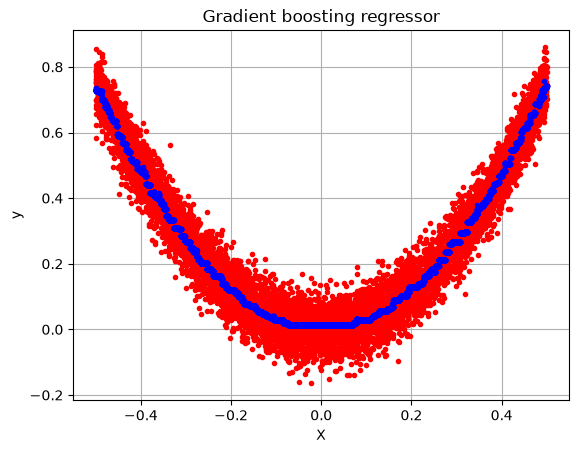

In [12]:
# Graficar los resultados
plt.plot(X, y, '.r')
plt.plot(X, y_pred, '.b')
plt.grid()
plt.xlabel('X')
plt.ylabel('y')
plt.title('Gradient boosting regressor')

In [13]:
mse = np.sum((y_pred - y) ** 2) / len(y)
print('MSE is : %1.6f' % mse)

MSE is : 0.002418


# Ejemplo paso a paso

In [14]:
import warnings
warnings.filterwarnings('ignore')

number_of_examples = 100
np.random.seed(42)
# generar las variables (features)
X = np.random.rand(number_of_examples, 1) - 0.5
# generar la variable objetivo (sin ruido esta vez, para que se vea mejor cada paso)
y = 3 * X[:, 0] ** 2 + 0.0 * np.random.randn(number_of_examples)
# crear un pandas.DataFrame
data = pd.DataFrame(data=np.stack([X[:, 0], y], axis=1), columns=["X", "y"])
data.head()

,X,y
0,-0.125460,0.047221
1,0.450714,0.609430
2,0.231994,0.161464
3,0.098658,0.029200
4,-0.343981,0.354970


In [15]:
# Primer árbol: ajustado directamente a los datos originales
tree_1 = DecisionTreeRegressor(max_depth=2)
tree_1.fit(X, y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",2
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with 

In [16]:
# Visualización del árbol omitida (dependía del paquete externo "hepml",
# eliminado de este notebook; ver la celda de la sección "Ejemplo").
# plot_regression_tree(tree_1, data.columns, fontsize=24)

In [17]:
data["Tree 1 prediction"] = tree_1.predict(X)
data.head()

,X,y,Tree 1 prediction
0,-0.125460,0.047221,0.132127
1,0.450714,0.609430,0.556216
2,0.231994,0.161464,0.132127
3,0.098658,0.029200,0.132127
4,-0.343981,0.354970,0.132127


In [18]:
def plot_predictions(regressors, X, y, axes, label=None, style="r-", data_style="b.", data_label=None):
    '''
    Grafica los datos de entrenamiento junto con la predicción combinada
    de una lista de regresores (la suma de sus predicciones individuales).
    Versión propia, usada en lugar de la de hepml para poder pasar
    `data_label` y mostrar la leyenda.
    '''
    x1 = np.linspace(axes[0], axes[1], 500)
    y_pred = sum(regressor.predict(x1.reshape(-1, 1)) for regressor in regressors)
    plt.plot(X[:, 0], y, data_style, label=data_label)
    plt.plot(x1, y_pred, style, linewidth=2, label=label)
    if label or data_label:
        plt.legend(loc="upper center", fontsize=16)
    plt.axis(axes)
    plt.ylabel("$y$", fontsize=16)
    plt.xlabel("$X$", fontsize=16)

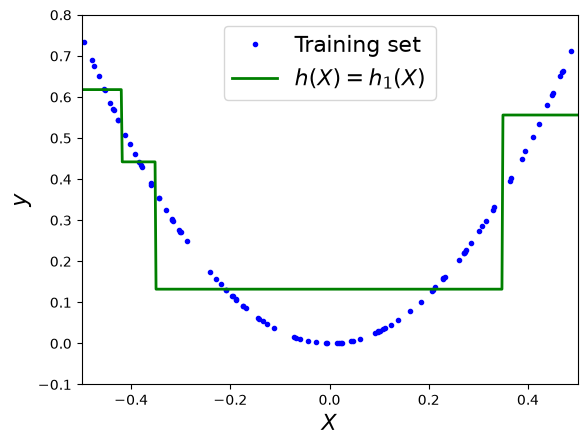

In [19]:
# Predicción del modelo usando solo el primer árbol: h(X) = h_1(X)
plot_predictions(
    [tree_1], X, y, axes=[-0.5, 0.5, -0.1, 0.8], label="$h(X)=h_1(X)$", style="g-", data_label="Training set"
)
plt.show()

In [20]:
# Residuo que le queda al modelo después del primer árbol
data["Tree 1 residual"] = data["y"] - data["Tree 1 prediction"]
data.head()

,X,y,Tree 1 prediction,Tree 1 residual
0,-0.125460,0.047221,0.132127,-0.084906
1,0.450714,0.609430,0.556216,0.053214
2,0.231994,0.161464,0.132127,0.029337
3,0.098658,0.029200,0.132127,-0.102926
4,-0.343981,0.354970,0.132127,0.222843


In [21]:
# Segundo árbol: ajustado a los residuos del primer árbol, no a y directamente
tree_2 = DecisionTreeRegressor(max_depth=2)
tree_2.fit(X, data["Tree 1 residual"])

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",2
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with 

In [22]:
data["Tree 2 prediction"] = tree_2.predict(X)
# predicción combinada del modelo tras dos árboles: F_2(X) = tree_1(X) + tree_2(X)
data["Tree 1 + tree 2 prediction"] = sum(tree.predict(X) for tree in (tree_1, tree_2))
data.head()

,X,y,Tree 1 prediction,Tree 1 residual,Tree 2 prediction,Tree 1 + tree 2 prediction
0,-0.125460,0.047221,0.132127,-0.084906,-0.082817,0.049310
1,0.450714,0.609430,0.556216,0.053214,0.049252,0.605468
2,0.231994,0.161464,0.132127,0.029337,0.049252,0.181379
3,0.098658,0.029200,0.132127,-0.102926,-0.082817,0.049310
4,-0.343981,0.354970,0.132127,0.222843,0.146027,0.278153


In [23]:
# Residuo que le queda al modelo después de los dos primeros árboles
data["Tree 1 + tree 2 residual"] = data["Tree 1 residual"] - data["Tree 2 prediction"]
data.head()

,X,y,Tree 1 prediction,Tree 1 residual,Tree 2 prediction,Tree 1 + tree 2 prediction,Tree 1 + tree 2 residual
0,-0.125460,0.047221,0.132127,-0.084906,-0.082817,0.049310,-0.002089
1,0.450714,0.609430,0.556216,0.053214,0.049252,0.605468,0.003962
2,0.231994,0.161464,0.132127,0.029337,0.049252,0.181379,-0.019915
3,0.098658,0.029200,0.132127,-0.102926,-0.082817,0.049310,-0.020109
4,-0.343981,0.354970,0.132127,0.222843,0.146027,0.278153,0.076816


In [24]:
# Tercer árbol: ajustado al residuo que dejaron los dos árboles anteriores
tree_3 = DecisionTreeRegressor(max_depth=2)
tree_3.fit(X, data["Tree 1 + tree 2 residual"])

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",2
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with 

In [25]:
data["Tree 3 prediction"] = tree_3.predict(X)
# predicción combinada del modelo tras tres árboles: F_3(X) = tree_1(X) + tree_2(X) + tree_3(X)
data["Tree 1 + tree 2 + tree 3 prediction"] = sum(tree.predict(X) for tree in (tree_1, tree_2, tree_3))
# residuo final que le queda al modelo después de los tres árboles
data["Final residual"] = data["Tree 1 + tree 2 residual"] - data["Tree 3 prediction"]
data.head()

,X,y,Tree 1 prediction,Tree 1 residual,Tree 2 prediction,Tree 1 + tree 2 prediction,Tree 1 + tree 2 residual,Tree 3 prediction,Tree 1 + tree 2 + tree 3 prediction,Final residual
0,-0.125460,0.047221,0.132127,-0.084906,-0.082817,0.049310,-0.002089,-0.000358,0.048951,-0.001731
1,0.450714,0.609430,0.556216,0.053214,0.049252,0.605468,0.003962,0.034388,0.639856,-0.030426
2,0.231994,0.161464,0.132127,0.029337,0.049252,0.181379,-0.019915,-0.000358,0.181020,-0.019557
3,0.098658,0.029200,0.132127,-0.102926,-0.082817,0.049310,-0.020109,-0.000358,0.048951,-0.019751
4,-0.343981,0.354970,0.132127,0.222843,0.146027,0.278153,0.076816,-0.000358,0.277795,0.077175


# Detención temprana (early stopping)

In [26]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=49)

# Entrenar con muchos árboles (120) y luego medir el error de validación
# etapa por etapa, para encontrar el número óptimo de árboles.
model = GradientBoostingRegressor(max_depth=2, n_estimators=120, random_state=42)
model.fit(X_train, y_train)

errors = [mean_squared_error(y_test, y_pred) for y_pred in model.staged_predict(X_test)]
best_n_estimators = np.argmin(errors) + 1

# Reentrenar solo con el número óptimo de árboles (detención temprana)
model_best = GradientBoostingRegressor(max_depth=2, n_estimators=best_n_estimators, random_state=42)
model_best.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",np.int64(105)
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range 

Text(0.5, 1.0, 'Validation error')

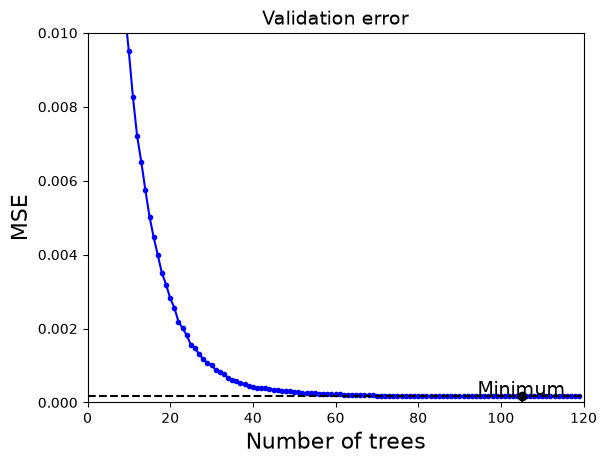

In [28]:
# Graficar el error de validación en función del número de árboles,
# marcando el mínimo (el punto de detención temprana)
min_error = np.min(errors)

plt.plot(errors, "b.-")
plt.plot([best_n_estimators, best_n_estimators], [0, min_error], "k--")
plt.plot([0, 120], [min_error, min_error], "k--")
plt.plot(best_n_estimators, min_error, "ko")
plt.text(best_n_estimators, min_error * 1.2, "Minimum", ha="center", fontsize=14)
plt.axis([0, 120, 0, 0.01])
plt.xlabel("Number of trees", fontsize=16)
plt.ylabel("MSE", fontsize=16)
plt.title("Validation error", fontsize=14)

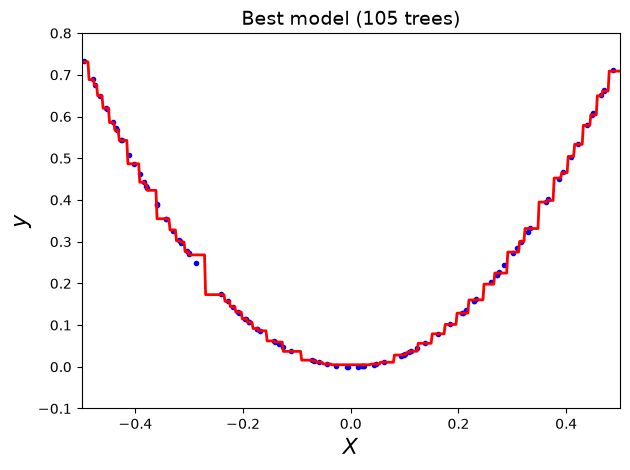

In [29]:
# Predicción final usando el modelo con el número óptimo de árboles
plot_predictions([model_best], X, y, axes=[-0.5, 0.5, -0.1, 0.8])
plt.title(f"Best model ({best_n_estimators} trees)", fontsize=14)

plt.tight_layout()